# 02 — Build the field table

**Purpose:** turn each FTW collection into one clean table with one row per field, holding its crop label, its split (train/val/test), its location and its AEF and OlmoEarth features. Notebook 03 trains on these tables.

For each collection, we download only the columns we need and keep a raw copy in `data/raw`. We drop fields with no label, duplicate ids, very small fields and crops with fewer than `MINFIELDS` fields. Large countries are capped at `MAXFIELDS` fields, sampled within each crop. Each field then gets its 256 embedding features and the split of the chip it overlaps most. We pilot each step on Estonia (`PILOT`), then run every collection in `COLLECTIONS`.

**Output:** `data/processed/fields_<collection>.parquet`, with columns `id`, `crop`, `chip`, `split`, `lon`, `lat`, `aef000`–`aef127` and `olmoearth000`–`olmoearth127`. For each model, features 0–63 are the per-field mean of the 64 embedding dimensions, and 64–127 are their standard deviation.

In [1]:
import fsspec
import shapely
import numpy as np
import pandas as pd
import geopandas as gpd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

Matplotlib is building the font cache; this may take a moment.


In [2]:
BENCHROOT    = 'https://data.source.coop/ftw/benchmark-data/'
RAWDIR       = Path('../data/raw')
PROCESSEDDIR = Path('../data/processed')
FIGDIR       = Path('../figs')
PILOT        = 'ee/ee_2024'
COLLECTIONS  = ['ee/ee_2024','sk/sk_2024','lv/lv_2024','cz/cz_2024','be_vlg/be_vlg_2024','dk/dk_2024','es_cat/es_cat_2024','si/si_2024','fi/fi_2024',
                'ie/ie_2024','se/se_2024','lt/lt_2024','hr/hr_2024','nl/nl_2024','es_vc/es_vc_2024','at/at_2024','es_cm/es_cm_2024','fr/fr_2024']
MAXFIELDS    = 200000
MINFIELDS    = 100
MINPIXELS    = 5
DROPCROPS    = []
SEED         = 42
SPLITS       = ['train','val','test']
SPLITCOLORS  = {'train':'#2a78d6','val':'#eb6834','test':'#1baf7a'}
MODELS       = ['aef','olmoearth']
FIELDCOLUMNS = ['id','hcat:code','hcat:name','geometry']
EMBEDCOLUMNS = ['id','pixels','pixel_rule','aef_mean','aef_std','olmoearth_mean','olmoearth_std']
CHIPCOLUMNS  = ['id','split','geometry']
FS           = fsspec.filesystem('https')
RAWDIR.mkdir(parents=True,exist_ok=True)
PROCESSEDDIR.mkdir(parents=True,exist_ok=True)
FIGDIR.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.color':'#e5e5e5','axes.axisbelow':True})

`MAXFIELDS = 200000` keeps all of Estonia and cuts France from 9.7 M fields to a size a CPU can train on. `MINPIXELS = 5` sets the minimum field size at five 10 m pixels (0.05 ha). `DROPCROPS` lists crops to leave out on purpose. It's empty for now; add `'fallow_land_not_crop'` if we decide fallow land doesn't count as a crop.

In [3]:
def asset_url(collection,key):
    return f"{BENCHROOT}{collection}/{collection.split('/')[1]}_{key}.parquet"

def raw_path(collection,key):
    return RAWDIR/f"{collection.split('/')[1]}_{key}.parquet"

def remote_size(collection,key):
    with FS.open(asset_url(collection,key),block_size=2**20) as f:
        return pq.ParquetFile(f).metadata.num_rows,FS.size(asset_url(collection,key))/1e6

def download(collection,key,columns):
    filepath = raw_path(collection,key)
    if not filepath.exists():
        partpath = filepath.with_suffix('.part')
        with FS.open(asset_url(collection,key),block_size=2**24) as f:
            pfile  = pq.ParquetFile(f)
            schema = pa.schema([pfile.schema_arrow.field(column) for column in columns],metadata=pfile.schema_arrow.metadata)
            with pq.ParquetWriter(partpath,schema,compression='zstd') as writer:
                for batch in pfile.iter_batches(batch_size=100000,columns=columns):
                    writer.write_batch(batch)
        partpath.rename(filepath)
    nrows = pq.ParquetFile(filepath).metadata.num_rows
    print(f'{key}: {nrows:,} rows ({filepath.stat().st_size/1e6:,.0f} MB) in {filepath}')

def drop_fields(table,keep,reason):
    print(f'Dropped {(~keep).sum():,} fields {reason}; {keep.sum():,} remain')
    return table[keep]

def save_figure(fig,name):
    filepath = FIGDIR/f'{name}.png'
    fig.savefig(filepath,bbox_inches='tight',dpi=200)
    print(f'Saved figure to {filepath}')

## 1. Download (Estonia pilot)

First the size of each file, for the pilot and for all collections. We download fewer columns than this, so the raw copies come out smaller.

In [4]:
sizes = pd.DataFrame([(collection,key,*remote_size(collection,key)) for collection in COLLECTIONS for key in ('fields','field_embeddings','chips')],
                     columns=['collection','key','nrows','sizemb'])
pilot = sizes[sizes.collection==PILOT]
print(f"Pilot {PILOT}: "+', '.join(f'{row.key} {row.nrows:,} rows ({row.sizemb:,.0f} MB)' for row in pilot.itertuples()))
print(f'All {len(COLLECTIONS)} collections: {sizes.sizemb.sum()/1e3:,.1f} GB in total, {sizes[sizes.key=="field_embeddings"].sizemb.sum()/1e3:,.1f} GB of it embeddings')

Pilot ee/ee_2024: fields 166,500 rows (278 MB), field_embeddings 166,500 rows (154 MB), chips 7,562 rows (1 MB)
All 18 collections: 45.8 GB in total, 29.7 GB of it embeddings


In [5]:
for key,columns in (('fields',FIELDCOLUMNS),('field_embeddings',EMBEDCOLUMNS),('chips',CHIPCOLUMNS)):
    download(PILOT,key,columns)

fields: 166,500 rows (279 MB) in ../data/raw/ee_2024_fields.parquet
field_embeddings: 166,500 rows (159 MB) in ../data/raw/ee_2024_field_embeddings.parquet
chips: 7,562 rows (0 MB) in ../data/raw/ee_2024_chips.parquet


## 2. Clean the labels

Load only the label and pixel-count columns (no geometry or embeddings yet), then drop unusable fields step by step.

In [6]:
def load_labels(collection):
    labels = pd.read_parquet(raw_path(collection,'fields'),columns=['id','hcat:code','hcat:name'])
    pixels = pd.read_parquet(raw_path(collection,'field_embeddings'),columns=['id','pixels','pixel_rule'])
    return labels.merge(pixels.drop_duplicates('id'),on='id',how='left')

def clean_labels(labels):
    print(f'Starting with {len(labels):,} fields')
    labels = drop_fields(labels,labels['hcat:code'].notna(),'with no HCAT label')
    labels = drop_fields(labels,~labels.id.duplicated(keep=False),'with a duplicated id')
    labels = drop_fields(labels,labels.pixels.notna(),'with no embedding row')
    labels = drop_fields(labels,(labels.pixels>=MINPIXELS)&(labels.pixel_rule!='touched'),f'smaller than {MINPIXELS} pixels')
    labels = drop_fields(labels,~labels['hcat:name'].isin(DROPCROPS),f"in DROPCROPS ({', '.join(DROPCROPS) or 'none'})")
    counts = labels['hcat:name'].value_counts()
    rare   = counts[counts<MINFIELDS]
    print(f"{len(rare)} of {len(counts)} crops have < {MINFIELDS} fields and are dropped: {', '.join(f'{name} ({n})' for name,n in rare.items())}")
    return drop_fields(labels,~labels['hcat:name'].isin(rare.index),'in those rare crops')

In [7]:
labels = clean_labels(load_labels(PILOT))

Starting with 166,500 fields
Dropped 0 fields with no HCAT label; 166,500 remain
Dropped 0 fields with a duplicated id; 166,500 remain
Dropped 0 fields with no embedding row; 166,500 remain
Dropped 3,139 fields smaller than 5 pixels; 163,361 remain
Dropped 0 fields in DROPCROPS (none); 163,361 remain
86 of 122 crops have < 100 fields and are dropped: blueberry (99), sunflower (84), lolium_ryegrass (76), nurseries_nursery (68), carrots_daucus (59), beetroot_beets (57), white_cabbage (54), onions (49), coriander (47), pumpkin_squash_gourd (46), millet_sorghum (42), aronia_chokeberries (41), garlic (40), aromatic_medicinal_culinary_plants_spices_herbs (37), kitchen_gardens (37), spelt (36), turnips (35), cucumber_pickle (30), caraway (30), vineyards_wine_vine_rebland_grapes (29), brassica_oleracea_cabbage (28), redcurrant (26), other_industrial_crops (25), vetches (25), marian_thistles (23), pears (22), plums (22), honeysuckle (22), galega (21), swede_rutabaga (21), anethum_dill (20), che

## 3. Cap large countries

If a collection has more than `MAXFIELDS` fields, keep the same share of every crop (at least `MINFIELDS` each), so crop proportions stay the same. Estonia is under the cap, so nothing changes here.

In [8]:
def cap_fields(labels):
    if len(labels)<=MAXFIELDS:
        print(f'{len(labels):,} fields is under the cap of {MAXFIELDS:,}; keeping all')
        return labels
    quota    = (labels['hcat:name'].value_counts()*MAXFIELDS/len(labels)).round().clip(lower=MINFIELDS)
    shuffled = labels.sample(frac=1,random_state=SEED)
    capped   = shuffled[shuffled.groupby('hcat:name').cumcount()<shuffled['hcat:name'].map(quota)]
    print(f"Sampled {len(capped):,} of {len(labels):,} fields ({len(capped)/len(labels):.1%}) across {capped['hcat:name'].nunique()} crops")
    return capped

In [9]:
labels = cap_fields(labels)

161,781 fields is under the cap of 200,000; keeping all


## 4. Embedding features

Read the AEF and OlmoEarth mean/std for the kept fields only, and spread each list of 64 numbers into its own columns. Fields with a missing or non-finite value are dropped.

In [10]:
def load_features(collection,ids):
    statcolumns = [f'{model}_{stat}' for model in MODELS for stat in ('mean','std')]
    table = pq.read_table(raw_path(collection,'field_embeddings'),columns=['id']+statcolumns,filters=pc.field('id').isin(ids))
    valid = np.all([pc.is_valid(table[column]).to_numpy(zero_copy_only=False) for column in statcolumns],axis=0)
    print(f'Read embeddings for {len(table):,} fields; {(~valid).sum():,} have a missing mean or std')
    table = table.filter(pa.array(valid))
    blocks = [pd.DataFrame(np.hstack([np.stack(table[f'{model}_{stat}'].to_numpy(zero_copy_only=False)) for stat in ('mean','std')]).astype('float32'),
                           columns=[f'{model}{i:03d}' for i in range(128)]) for model in MODELS]
    features = pd.concat([pd.DataFrame({'id':table['id'].to_numpy(zero_copy_only=False)})]+blocks,axis=1)
    return drop_fields(features,np.isfinite(features.iloc[:,1:].to_numpy()).all(axis=1),'with non-finite features')

In [11]:
features = load_features(PILOT,labels.id.tolist())
print(f'Feature table: {features.shape[0]:,} fields × {features.shape[1]-1} features ({features.memory_usage().sum()/1e6:,.0f} MB)')

Read embeddings for 161,781 fields; 0 have a missing mean or std


Dropped 0 fields with non-finite features; 161,781 remain
Feature table: 161,781 fields × 256 features (168 MB)


## 5. Location and split

The centroid gives each field's lon/lat (it is computed in an equal-area projection, EPSG:3035, then converted back). Invalid polygons (for example, ones whose outline crosses itself) are repaired first. The split comes from the chips: we find every chip a field touches and keep the one it overlaps most. Fields that touch no chip get no split and are dropped.

In [12]:
def locate_fields(collection,ids):
    geoms     = gpd.read_parquet(raw_path(collection,'fields'),columns=['id','geometry'],filters=pc.field('id').isin(ids))
    chips     = gpd.read_parquet(raw_path(collection,'chips')).rename(columns={'id':'chip'})
    invalid   = ~geoms.is_valid
    geoms.loc[invalid,'geometry'] = geoms.geometry[invalid].make_valid()
    print(f'Repaired {invalid.sum():,} invalid field polygons')
    centroids = geoms.geometry.to_crs(3035).centroid.to_crs(4326)
    location  = pd.DataFrame({'id':geoms.id,'lon':centroids.x,'lat':centroids.y})
    pairs     = gpd.sjoin(geoms,chips,predicate='intersects')
    pairs['overlap'] = shapely.area(shapely.intersection(np.asarray(pairs.geometry),np.asarray(chips.geometry)[pairs.index_right]))
    best      = pairs.sort_values('overlap').drop_duplicates('id',keep='last')[['id','chip','split']]
    print(f"{pairs.id.nunique():,} of {len(geoms):,} fields touch a chip; {(pairs.id.value_counts()>1).sum():,} touch more than one")
    location  = location.merge(best,on='id',how='left')
    return drop_fields(location,location.split.notna(),'outside every chip')

In [13]:
location = locate_fields(PILOT,features.id.tolist())
print(location.split.value_counts().reindex(SPLITS).to_string())

Repaired 14 invalid field polygons


141,670 of 161,781 fields touch a chip; 37,832 touch more than one
Dropped 20,111 fields outside every chip; 141,670 remain


split
train    112146
val       12871
test      16653


## 6. Join and save

Join the labels, location and features on `id`, check that each crop appears in every split, and save.

In [14]:
def join_and_save(collection,labels,location,features):
    table    = (labels[['id','hcat:name']].rename(columns={'hcat:name':'crop'})
                .merge(location,on='id',validate='one_to_one').merge(features,on='id',validate='one_to_one'))
    filepath = PROCESSEDDIR/f"fields_{collection.split('/')[1]}.parquet"
    table.to_parquet(filepath,index=False)
    print(f"Saved {len(table):,} fields, {table.crop.nunique()} crops, {table.shape[1]} columns ({filepath.stat().st_size/1e6:,.0f} MB) to {filepath}")
    return table

In [15]:
table   = join_and_save(PILOT,labels,location,features)
persplit = pd.crosstab(table.crop,table.split)[SPLITS].sort_values('train',ascending=False)
missing = persplit[(persplit==0).any(axis=1)]
print(f"{len(missing)} of {len(persplit)} crops are missing from at least one split{': '+', '.join(missing.index) if len(missing) else ''}")
display(persplit)

Saved 141,670 fields, 36 crops, 262 columns (224 MB) to ../data/processed/fields_ee_2024.parquet
0 of 36 crops are missing from at least one split


split,train,val,test
crop,,,
pasture_meadow_grassland_grass,48034,5400,7140
winter_common_soft_wheat,10592,1291,1674
legumes_harvested_green,8666,1089,1333
oats,5792,516,758
spring_barley,5250,616,823
clover,4863,535,749
peas,4426,506,784
spring_common_soft_wheat,3501,325,425
winter_rapeseed_rape,3501,336,487


## 7. Pilot figures

A map of the kept fields coloured by split. Whole blocks of fields share one colour, which is what keeps test fields away from training fields. Then the number of fields per crop, on a log scale because grassland alone is a third of the fields.

Saved figure to ../figs/02_split_map_ee_2024.png


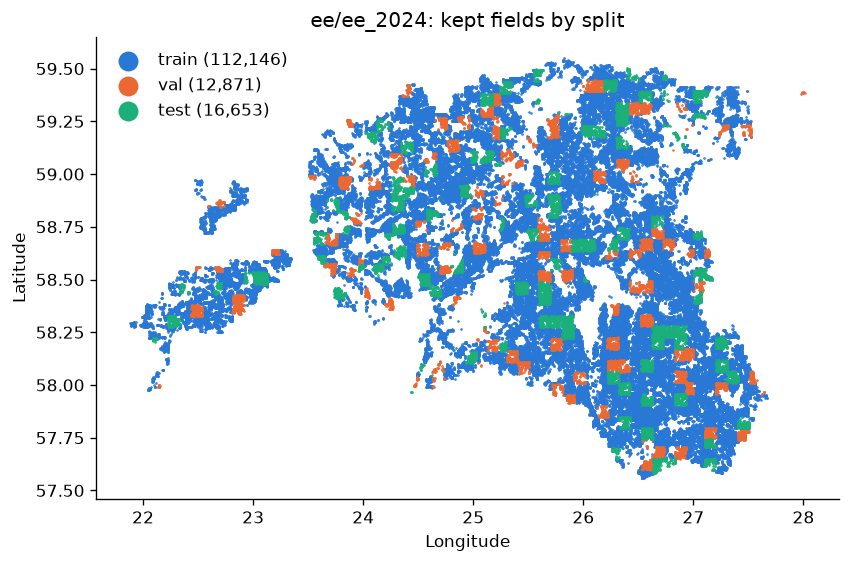

In [16]:
fig,ax = plt.subplots(figsize=(8,5))
for split in SPLITS:
    subset = table[table.split==split]
    ax.scatter(subset.lon,subset.lat,s=0.3,color=SPLITCOLORS[split],label=f'{split} ({len(subset):,})',rasterized=True)
ax.set_aspect(1/np.cos(np.radians(table.lat.mean())))
ax.set(xlabel='Longitude',ylabel='Latitude',title=f'{PILOT}: kept fields by split')
ax.grid(False)
ax.legend(markerscale=20,frameon=False,loc='upper left')
save_figure(fig,f"02_split_map_{PILOT.split('/')[1]}")
plt.show()

Saved figure to ../figs/02_crop_counts_ee_2024.png


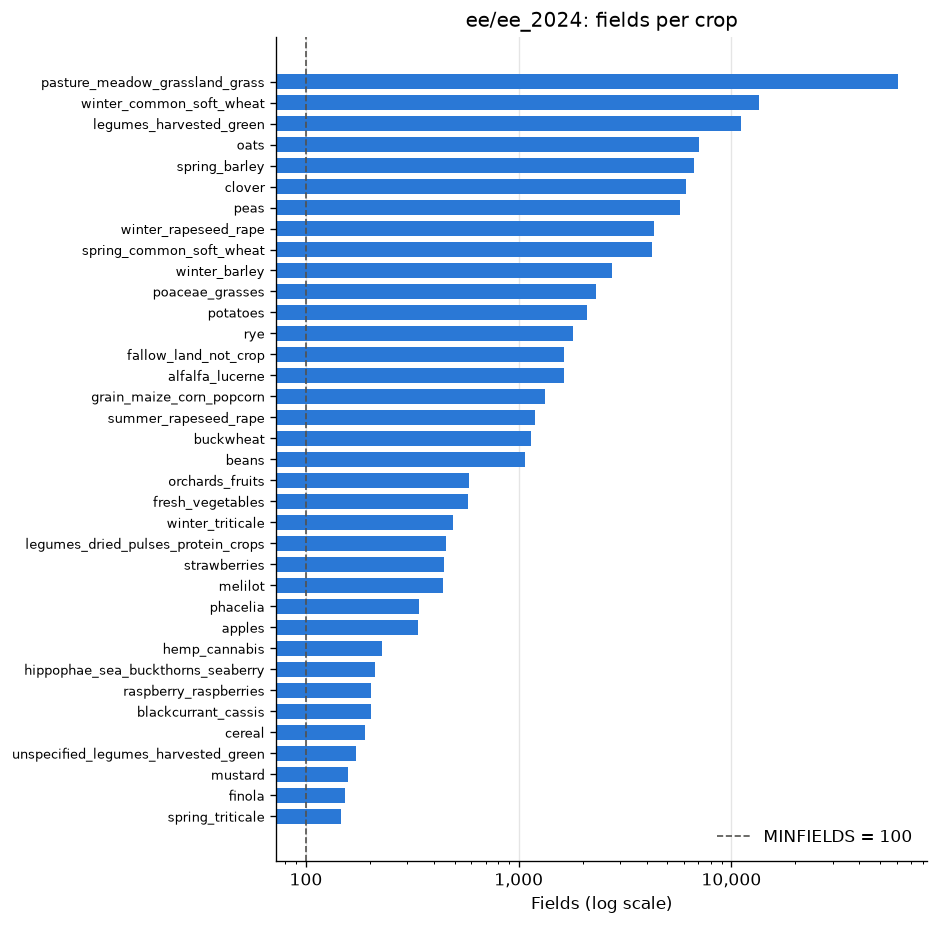

In [17]:
cropcounts = table.crop.value_counts().sort_values()
fig,ax = plt.subplots(figsize=(7,0.22*len(cropcounts)+1))
ax.barh(cropcounts.index,cropcounts.values,color=SPLITCOLORS['train'],height=0.7)
ax.axvline(MINFIELDS,color='#52514e',linewidth=1,linestyle='--',label=f'MINFIELDS = {MINFIELDS}')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(lambda x,_:f'{x:,.0f}')
ax.legend(frameon=False,loc='lower right')
ax.set(xlabel='Fields (log scale)',title=f'{PILOT}: fields per crop')
ax.grid(axis='y',visible=False)
ax.tick_params(axis='y',labelsize=8)
save_figure(fig,f"02_crop_counts_{PILOT.split('/')[1]}")
plt.show()

## 8. All collections

Run the same steps for every collection in `COLLECTIONS`, skipping any that already have an output file. The pilot tables are deleted first to free memory, and each table is saved and then dropped, so memory stays at the size of one collection. The largest download is France (about 9 GB of embeddings).

In [18]:
def build_table(collection):
    print(f'\n=== {collection} ===')
    for key,columns in (('fields',FIELDCOLUMNS),('field_embeddings',EMBEDCOLUMNS),('chips',CHIPCOLUMNS)):
        download(collection,key,columns)
    labels   = cap_fields(clean_labels(load_labels(collection)))
    features = load_features(collection,labels.id.tolist())
    location = locate_fields(collection,features.id.tolist())
    join_and_save(collection,labels,location,features)

In [19]:
del labels,features,location,table
todo = [collection for collection in COLLECTIONS if not (PROCESSEDDIR/f"fields_{collection.split('/')[1]}.parquet").exists()]
print(f'{len(todo)} of {len(COLLECTIONS)} collections still to build')
for collection in todo:
    build_table(collection)

17 of 18 collections still to build

=== sk/sk_2024 ===
fields: 275,049 rows (493 MB) in ../data/raw/sk_2024_fields.parquet
field_embeddings: 275,049 rows (262 MB) in ../data/raw/sk_2024_field_embeddings.parquet
chips: 9,986 rows (1 MB) in ../data/raw/sk_2024_chips.parquet


Starting with 275,049 fields
Dropped 4,564 fields with no HCAT label; 270,485 remain
Dropped 0 fields with a duplicated id; 270,485 remain
Dropped 0 fields with no embedding row; 270,485 remain
Dropped 1,494 fields smaller than 5 pixels; 268,991 remain
Dropped 0 fields in DROPCROPS (none); 268,991 remain
84 of 128 crops have < 100 fields and are dropped: buckwheat (98), peach (88), pears (77), carrots_daucus (69), spring_rapeseed_rape (69), nurseries_nursery (69), temporary_grass (67), sweet_lupins (65), beetroot_beets (64), beans (58), cherry_cherries (55), rapeseed_rape (53), populus (49), winter_oats (46), garlic (45), blueberry (43), parsly (41), aronia_chokeberries (41), bell_pepper_paprika (40), willows_osiers (39), spinach (39), flax_linseed_oil (38), onobrychis_sainfoins (37), currants (34), mangelwurzel_fodder_beet (34), flowers_ornamental_plants (34), hemp_cannabis (33), hippophae_sea_buckthorns_seaberry (28), lentils (25), zucchini_courgette (24), watermelon (24), melon (21)

Sampled 200,034 of 267,123 fields (74.9%) across 44 crops


Read embeddings for 200,034 fields; 0 have a missing mean or std


Dropped 0 fields with non-finite features; 200,034 remain


Repaired 98 invalid field polygons


... (189 outputs left out)

Dropped 0 fields with non-finite features; 202,524 remain


Repaired 2 invalid field polygons


196,055 of 202,524 fields touch a chip; 39,411 touch more than one
Dropped 6,469 fields outside every chip; 196,055 remain


Saved 196,055 fields, 93 crops, 262 columns (312 MB) to ../data/processed/fields_fr_2024.parquet


Fields per collection and split, read back from the saved tables (only the `split` column).

3,247,905 fields across 18 collections


Saved figure to ../figs/02_fields_per_collection.png


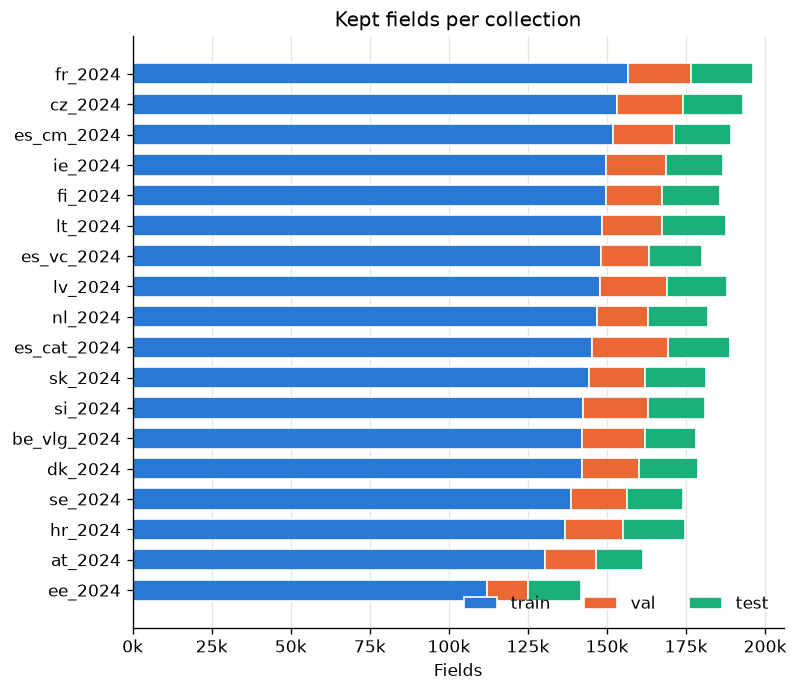

In [20]:
splitcounts = pd.DataFrame({collection.split('/')[1]:pd.read_parquet(PROCESSEDDIR/f"fields_{collection.split('/')[1]}.parquet",columns=['split']).split.value_counts()
                            for collection in COLLECTIONS}).T[SPLITS].sort_values('train')
print(f'{splitcounts.values.sum():,} fields across {len(splitcounts)} collections')
fig,ax = plt.subplots(figsize=(7,0.3*len(splitcounts)+1))
left = np.zeros(len(splitcounts))
for split in SPLITS:
    ax.barh(splitcounts.index,splitcounts[split],left=left,color=SPLITCOLORS[split],height=0.7,label=split,edgecolor='white',linewidth=1)
    left += splitcounts[split].to_numpy()
ax.set(xlabel='Fields',title='Kept fields per collection')
ax.xaxis.set_major_formatter(lambda x,_:f'{x/1e3:,.0f}k')
ax.grid(axis='y',visible=False)
ax.legend(frameon=False,ncols=3,loc='lower right')
save_figure(fig,'02_fields_per_collection')
plt.show()

## Summary for notebook 03

*(Fill in once the loop has run: fields and crops kept per country, and any data issues found.)*